### Homework 01
Igor Di Tota

The following three cells are taken from the lecture notebook and are used to load the data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Data set to be used for the homework
hwlink = "https://www.fuw.edu.pl/~zarnecki/SAED/OECD_Poland_filtered.csv"

# Reading from the web (relevant columns only)
hw= pd.read_csv(hwlink, encoding='latin-1', sep=",", usecols=['SEX','Sex','AGE','Age','TIME_PERIOD','OBS_VALUE'])  # Columns are counted from 0 (!)

print(hw)

     SEX     Sex     AGE                  Age  TIME_PERIOD  OBS_VALUE
0      F  Female  Y_GE50     50 years or over         1960  3379322.0
1      F  Female  Y_GE50     50 years or over         1961  3403900.0
2      F  Female  Y_GE50     50 years or over         1962  3502400.0
3      F  Female  Y_GE50     50 years or over         1963  3625100.0
4      F  Female  Y_GE50     50 years or over         1964  3728901.0
...   ..     ...     ...                  ...          ...        ...
3643   F  Female  Y_GE50     50 years or over         2025  8215716.0
3644   F  Female   Y_LE4      4 years or less         2025   707100.0
3645   F  Female  Y55T59  From 55 to 59 years         2025  1115886.0
3646   F  Female  Y30T34  From 30 to 34 years         2025  1198754.0
3647   F  Female  Y15T19  From 15 to 19 years         2025   987098.0

[3648 rows x 6 columns]


In [2]:
# List of age categories in the data set

AgeList = hw.drop_duplicates(subset='AGE',ignore_index=True)

ncat = AgeList.shape[0]

print(ncat," age categories found in the data base:")

for icat in range(ncat):
    print("    {:6s}  =>  {:s}".format(AgeList.at[icat,"AGE"],AgeList.at[icat,"Age"]))

24  age categories found in the data base:
    Y_GE50  =>  50 years or over
    Y80T84  =>  From 80 to 84 years
    Y25T29  =>  From 25 to 29 years
    Y_LT20  =>  Less than 20 years
    Y15T64  =>  From 15 to 64 years
    Y20T64  =>  From 20 to 64 years
    Y15T19  =>  From 15 to 19 years
    Y45T49  =>  From 45 to 49 years
    Y_GE85  =>  85 years or over
    Y60T64  =>  From 60 to 64 years
    Y40T44  =>  From 40 to 44 years
    Y20T24  =>  From 20 to 24 years
    Y_LE4   =>  4 years or less
    Y10T14  =>  From 10 to 14 years
    _T      =>  Total
    Y55T59  =>  From 55 to 59 years
    Y75T79  =>  From 75 to 79 years
    Y35T39  =>  From 35 to 39 years
    Y30T34  =>  From 30 to 34 years
    Y5T9    =>  From 5 to 9 years
    Y70T74  =>  From 70 to 74 years
    Y_GE65  =>  65 years or over
    Y50T54  =>  From 50 to 54 years
    Y65T69  =>  From 65 to 69 years


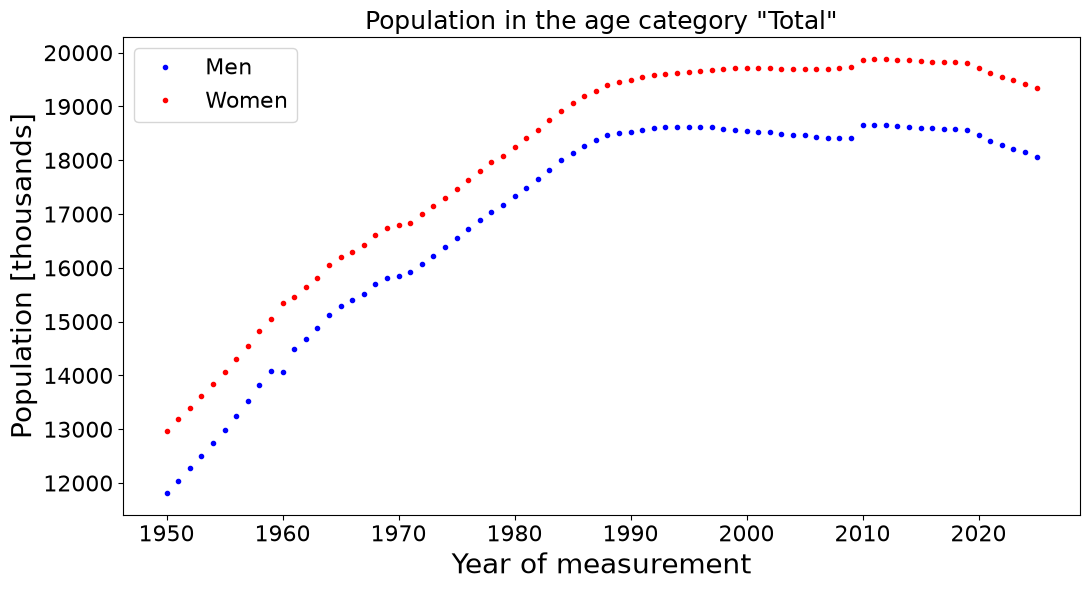

In [3]:
# Select age category for the plot

MyAge = "_T"    
# MyAge = "Y35T39"  # Try to uncomment and see the result. Can you explain it?!

# Flag for selecting age category

inage = hw["AGE"] == MyAge

AgeName = hw["Age"][inage].iat[0]
    
# Flags to select rows with given sex

isman = hw["Sex"] == "Male"
iswom = hw["Sex"] == "Female"

# Extract numpy arrays with years and population count in given age range

nman = hw["OBS_VALUE"][isman * inage].to_numpy()
yman = hw["TIME_PERIOD"][isman * inage].to_numpy()

nwom = hw["OBS_VALUE"][iswom * inage].to_numpy()
ywom = hw["TIME_PERIOD"][iswom * inage].to_numpy()


# Plot population vs year 

plt.figure(figsize=(11, 6))

plt.plot(yman,nman/1000.,'.',label='Men', c = 'blue')
plt.plot(ywom,nwom/1000.,'.',label='Women', c = 'red')

plt.xlabel('Year of measurement',size=20)
plt.ylabel('Population [thousands]',size=20)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.title("Population in the age category \""+AgeName+"\"",size=18)
plt.legend(title='',fontsize=16)

fname = '01_Homework'+MyAge+'.png'

plt.tight_layout()
plt.savefig(fname)

plt.show()

In this cell I want to better understand the age groups used in the dataset.
First, I create an ordered list of age groups, then I add the aggregate variables.\
The 24 variables are shown below.

       AGE                  Age          type
0    Y_LE4      4 years or less  5-year group
1     Y5T9    From 5 to 9 years  5-year group
2   Y10T14  From 10 to 14 years  5-year group
3   Y15T19  From 15 to 19 years  5-year group
4   Y20T24  From 20 to 24 years  5-year group
5   Y25T29  From 25 to 29 years  5-year group
6   Y30T34  From 30 to 34 years  5-year group
7   Y35T39  From 35 to 39 years  5-year group
8   Y40T44  From 40 to 44 years  5-year group
9   Y45T49  From 45 to 49 years  5-year group
10  Y50T54  From 50 to 54 years  5-year group
11  Y55T59  From 55 to 59 years  5-year group
12  Y60T64  From 60 to 64 years  5-year group
13  Y65T69  From 65 to 69 years  5-year group
14  Y70T74  From 70 to 74 years  5-year group
15  Y75T79  From 75 to 79 years  5-year group
16  Y80T84  From 80 to 84 years  5-year group
17  Y_GE85     85 years or over  5-year group
18  Y_LT20   Less than 20 years     aggregate
19  Y15T64  From 15 to 64 years     aggregate
20  Y20T64  From 20 to 64 years   

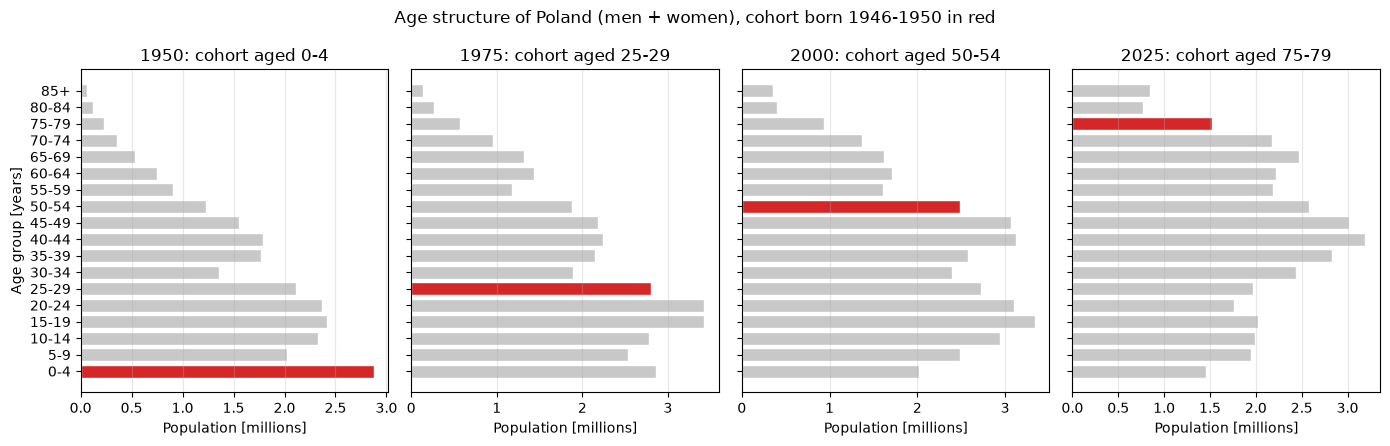

In [6]:

# The 5-year groups 0-4, 5-9, ..., 80-84 plus the open group 85+ form a partition of the population.
# All the other categories are aggregates of them.

groups = ["Y_LE4"] + [f"Y{a}T{a+4}" for a in range(5, 85, 5)] + ["Y_GE85"]
labels = ["0-4"] + [f"{a}-{a+4}" for a in range(5, 85, 5)] + ["85+"]
aggregates = ["Y_LT20", "Y15T64", "Y20T64", "Y_GE50", "Y_GE65", "_T"]

# Age categories available in the data set: 5-year groups in age order, then aggregates
# (sorting by the code itself is alphabetical and would put "Y5T9" after "Y55T59")
cats = (hw[["AGE", "Age"]].drop_duplicates().set_index("AGE")
        .loc[groups + aggregates].reset_index())
cats["type"] = ["5-year group"] * len(groups) + ["aggregate"] * len(aggregates)
print(cats.to_string())


# Age distribution (men + women) in four years: the 1946-1950 cohort (highlighted)
# moves to the next 5-year group every 5 years
years = [1950, 1975, 2000, 2025]
fig, axes = plt.subplots(1, len(years), figsize=(14, 4.5), sharey=True)
for ax, year in zip(axes, years):
    pop = (hw[(hw.TIME_PERIOD == year) & hw.AGE.isin(groups)]
           .groupby("AGE").OBS_VALUE.sum()[groups] / 1e6)
    k = (year - 1950) // 5
    colors = ["#c8c8c8"] * len(groups)
    colors[k] = "#d62728"
    ax.barh(labels, pop, color=colors, edgecolor="white", linewidth=1)
    ax.set_title(f"{year}: cohort aged {labels[k]}")
    ax.set_xlabel("Population [millions]")
    ax.grid(axis="x", alpha=0.3)
axes[0].set_ylabel("Age group [years]")
fig.suptitle("Age structure of Poland (men + women), cohort born 1946-1950 in red")
fig.tight_layout()
plt.show()

sex  year age_group          F          M
0    1950       0-4  1411228.0  1461961.5
1    1955       5-9  1372292.5  1416045.0
2    1960     10-14  1492965.0  1547047.0
3    1965     15-19  1421300.0  1470800.0
4    1970     20-24  1458565.0  1498807.0
5    1975     25-29  1384379.0  1415026.0
6    1980     30-34  1372676.0  1395701.0
7    1985     35-39  1359932.0  1371361.0
8    1990     40-44  1218442.0  1209059.0
9    1995     45-49  1281691.0  1244809.0
10   2000     50-54  1286469.0  1201828.0
11   2005     55-59  1251972.0  1122211.0
12   2010     60-64  1209910.0  1038241.0
13   2015     65-69  1147725.0   917893.0
14   2020     70-74  1055486.0   773122.0
15   2025     75-79   923155.0   603409.0


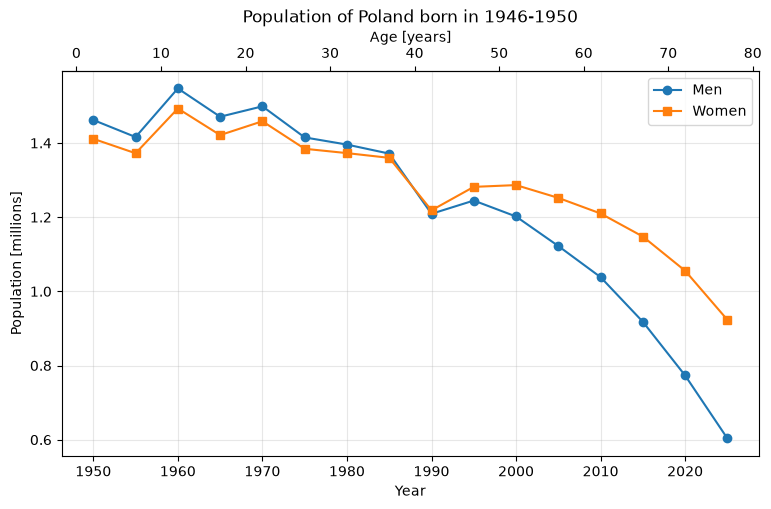

In [5]:
# Task 1: population of men and women born in 1946-1950 as a function of year (and age)

# The 1946-1950 cohort is aged 0-4 in 1950, 5-9 in 1955, ..., 75-79 in 2025:
# in year 1950 + 5k it is in the age group [5k, 5k+4]
rows = []
for k in range(16):
    year = 1950 + 5 * k
    age_code = "Y_LE4" if k == 0 else f"Y{5*k}T{5*k+4}"
    for sex in ["M", "F"]:
        sel = hw[(hw.SEX == sex) & (hw.AGE == age_code) & (hw.TIME_PERIOD == year)]
        rows.append({"year": year, "age_group": f"{5*k}-{5*k+4}", "sex": sex,
                     "population": sel.OBS_VALUE.iloc[0]})

cohort = pd.DataFrame(rows).pivot(index=["year", "age_group"], columns="sex",
                                  values="population").reset_index()
print(cohort)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(cohort.year, cohort.M / 1e6, "o-", label="Men")
ax.plot(cohort.year, cohort.F / 1e6, "s-", label="Women")
ax.set_xlabel("Year")
ax.set_ylabel("Population [millions]")
ax.set_title("Population of Poland born in 1946-1950", pad=35)
ax.grid(alpha=0.3)
ax.legend()

# secondary x axis with the age of the cohort (centre of the age group)
sec = ax.secondary_xaxis("top", functions=(lambda y: y - 1950 + 2, lambda a: a + 1950 - 2))
sec.set_xlabel("Age [years]")

plt.show()